In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import copy
import math

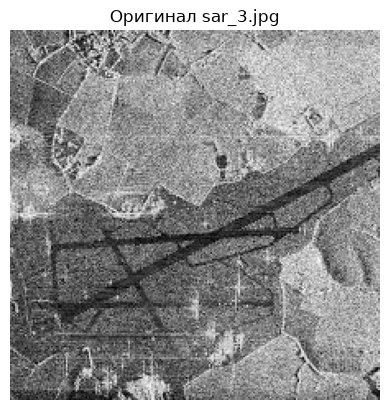

Размер: (225, 225)


In [2]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

plt.imshow(image_gray, cmap='gray')
plt.title('Оригинал sar_3.jpg')
plt.axis('off')
plt.show()

print("Размер:", image_gray.shape)

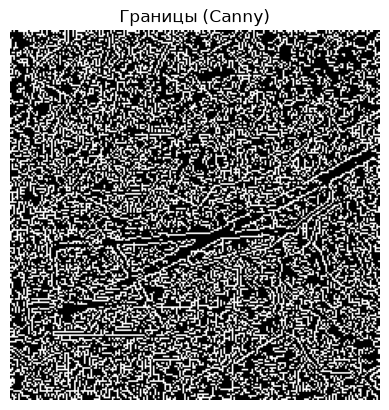

In [3]:
# Выделение границ
edges = cv2.Canny(image_gray, 100, 200)

plt.imshow(edges, cmap='gray')
plt.title('Границы (Canny)')
plt.axis('off')
plt.show()

In [4]:
# Преобразование Хафа
lines = cv2.HoughLines(edges, 1, np.pi / 180, 150)

print("Найдено линий:", 0 if lines is None else len(lines))

Найдено линий: 6


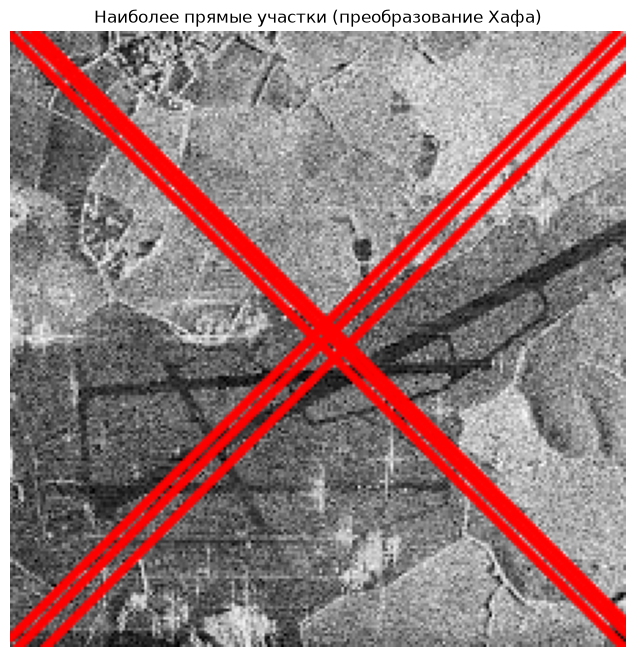

In [5]:
# Копия исходного изображения для отрисовки
image_hough = image.copy()

if lines is not None:
    for i in range(len(lines)):
        rho = lines[i][0][0]
        theta = lines[i][0][1]
        a = math.cos(theta)
        b = math.sin(theta)
        x0 = a * rho
        y0 = b * rho
        pt1 = (int(x0 + 1000 * (-b)), int(y0 + 1000 * (a)))
        pt2 = (int(x0 - 1000 * (-b)), int(y0 - 1000 * (a)))
        cv2.line(image_hough, pt1, pt2, (0, 0, 255), 2, cv2.LINE_AA)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(image_hough, cv2.COLOR_BGR2RGB))
plt.title('Наиболее прямые участки (преобразование Хафа)')
plt.axis('off')
plt.show()

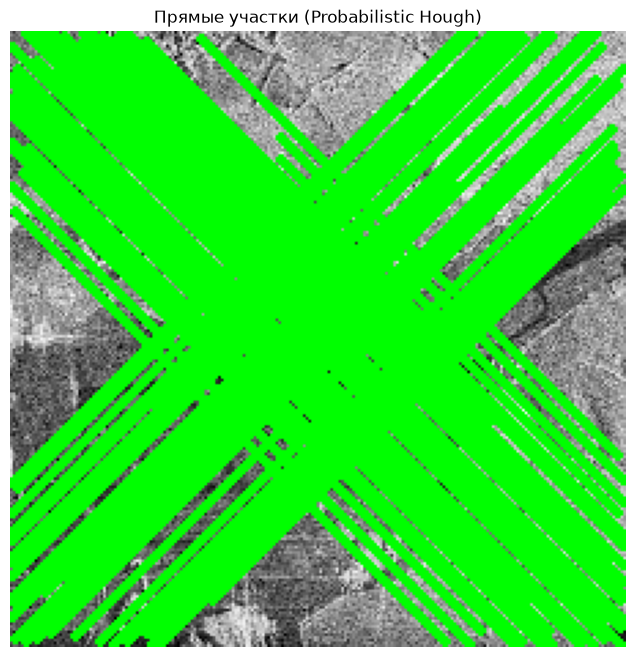

=== Задание 1. Преобразование Хафа ===
Найдено прямых (HoughLines):   6
Найдено отрезков (HoughLinesP): 61


In [7]:
# Probabilistic Hough Transform
lines_p = cv2.HoughLinesP(edges, 1, np.pi / 180, threshold=100,
                          minLineLength=100, maxLineGap=10)

image_hough_p = image.copy()

if lines_p is not None:
    # Приводим форму к (N, 4) — на случай разных версий OpenCV
    lines_p_flat = lines_p.reshape(-1, 4)
    for x1, y1, x2, y2 in lines_p_flat:
        cv2.line(image_hough_p, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 2)

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(image_hough_p, cv2.COLOR_BGR2RGB))
plt.title('Прямые участки (Probabilistic Hough)')
plt.axis('off')
plt.show()

print("=== Задание 1. Преобразование Хафа ===")
print(f"Найдено прямых (HoughLines):   {0 if lines is None else len(lines)}")
print(f"Найдено отрезков (HoughLinesP): {0 if lines_p is None else len(lines_p)}")

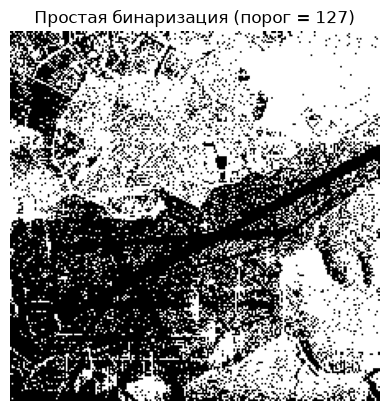

In [8]:
# Простая бинаризация
ret, th_binary = cv2.threshold(image_gray, 127, 255, cv2.THRESH_BINARY)

plt.imshow(th_binary, cmap='gray')
plt.title('Простая бинаризация (порог = 127)')
plt.axis('off')
plt.show()

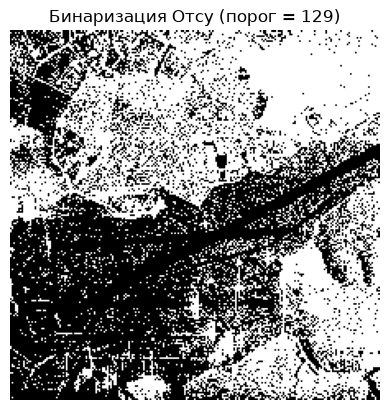

Порог Отсу: 129.00


In [9]:
# Бинаризация Отсу
ret_otsu, th_otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

plt.imshow(th_otsu, cmap='gray')
plt.title(f'Бинаризация Отсу (порог = {ret_otsu:.0f})')
plt.axis('off')
plt.show()

print(f"Порог Отсу: {ret_otsu:.2f}")

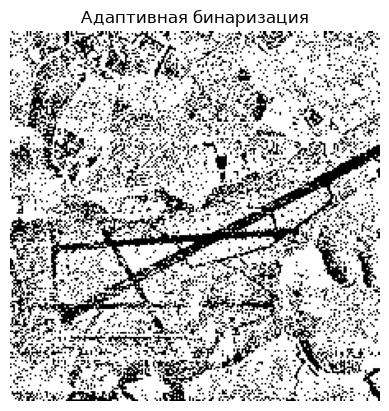

In [10]:
# Адаптивная бинаризация
th_adaptive = cv2.adaptiveThreshold(
    image_gray, 255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    71, 21
)

plt.imshow(th_adaptive, cmap='gray')
plt.title('Адаптивная бинаризация')
plt.axis('off')
plt.show()

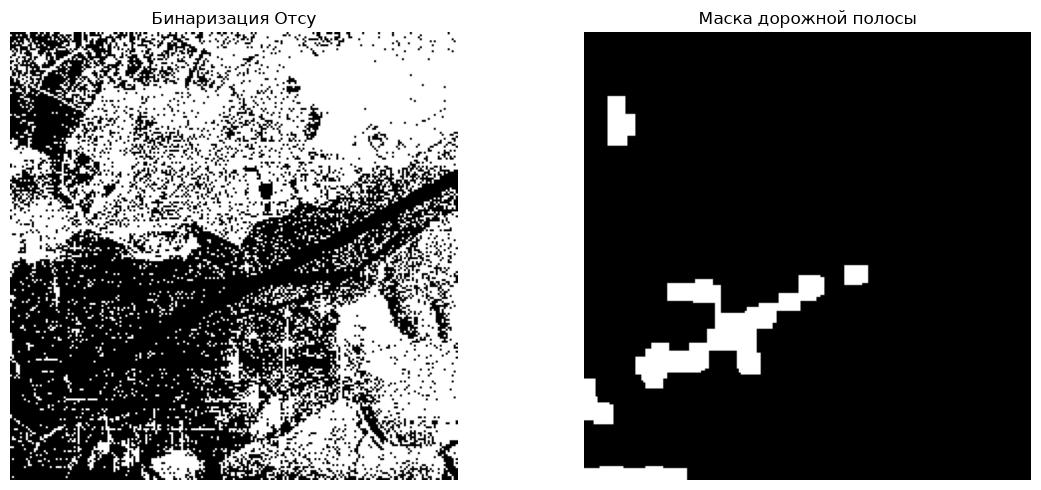

In [11]:
# Инвертируем бинаризацию Отсу — дорога (тёмная) станет белой
road_mask = cv2.bitwise_not(th_otsu)

# Морфология: убираем мелкий шум
kernel = np.ones((5, 5), np.uint8)
road_mask = cv2.morphologyEx(road_mask, cv2.MORPH_OPEN, kernel, iterations=2)
road_mask = cv2.morphologyEx(road_mask, cv2.MORPH_CLOSE, kernel, iterations=2)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1), plt.imshow(th_otsu, cmap='gray'), plt.title('Бинаризация Отсу'), plt.axis('off')
plt.subplot(1, 2, 2), plt.imshow(road_mask, cmap='gray'), plt.title('Маска дорожной полосы'), plt.axis('off')
plt.tight_layout()
plt.show()


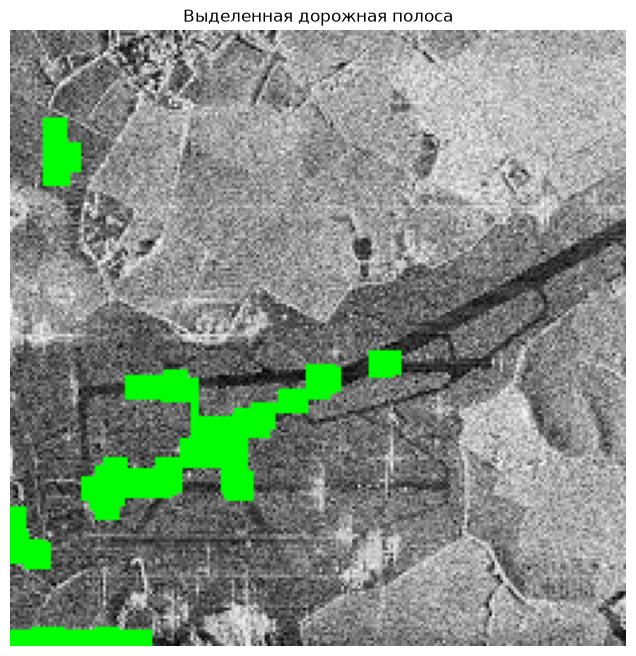

In [12]:
# Наложение маски дороги на цветное изображение
result = image.copy()
result[road_mask == 255] = [0, 255, 0]   # дорога — зелёным цветом

plt.figure(figsize=(10, 8))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title('Выделенная дорожная полоса')
plt.axis('off')
plt.show()

In [13]:
print("=== Задание 2. Бинаризация и дорожная полоса ===")
print(f"Размер изображения:      {image_gray.shape}")
print(f"Порог Отсу:              {ret_otsu:.2f}")
print(f"Пикселей в маске дороги: {int((road_mask == 255).sum())}")
print(f"Доля дороги от кадра:    {(road_mask == 255).mean() * 100:.2f}%")

=== Задание 2. Бинаризация и дорожная полоса ===
Размер изображения:      (225, 225)
Порог Отсу:              129.00
Пикселей в маске дороги: 2775
Доля дороги от кадра:    5.48%
